# Checkpoint: steps 1–3 on the daylight set

AUC Campus Landmark Recognizer · CSCE 4603 · Fall 2026

1. **Data**: rename, label, resize and load the photos
2. **Keypoints**: Harris vs SIFT, and how repeatable each is
3. **Matching**: SIFT ratio test, then RANSAC

Run from top to bottom (Kernel → Restart & Run All). Every figure is also saved to `results/`.

In [1]:
# %pip install -r requirements.txt
# %pip install pandas scikit-learn pillow

In [2]:
import sys
sys.path.append("..")
%load_ext autoreload
%autoreload 2

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.data import load_dataset, load_image, load_labels, resize_all
from src.evaluate import evaluate
from src.features import detect_harris, detect_sift, repeatability, sift_keypoints
from src.matching import draw_before_after, match_images
from src.organize import organize
from src.recognition import build_reference, match_counts, vote
from src.utils import save_figure, show

## Settings

In [3]:
DEMO_LANDMARK = "library"  # used for the single-photo figures
OTHER_LANDMARK = "seoudi"  # a different landmark, for the "no match" example

## Step 1 · Data

In [4]:
labels = organize()      # renames new photos in data/raw/ and rewrites labels.csv
resize_all()             # writes 1024 px copies to data/processed/
labels = load_labels()   # also warns if train and test photos share a day
labels.groupby(["landmark", "split"]).size().unstack(fill_value=0)

[organize] renamed 0 new photos; labels.csv has 66 rows
split           pano  train
landmark                   
admin_building     0      9
library            3      9
pepsi_gate         0      9
seoudi             0      9
sports_gate        0      9
sse                0      9
waterfall          0      9
[resize_all] wrote 0 photos to C:\Users\OMEN\Desktop\Mememe\college\semester 10\Computer vision\Project\auc-landmark-recognition\data\processed


split,pano,train
landmark,,
admin_building,0,9
library,3,9
pepsi_gate,0,9
seoudi,0,9
sports_gate,0,9
sse,0,9
waterfall,0,9


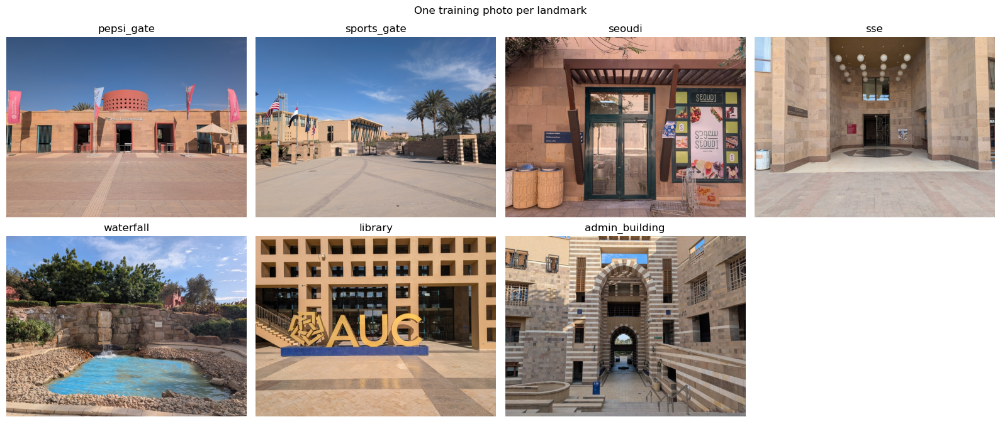

In [5]:
train = labels[labels["split"] == "train"].sort_values("filename")

def photo(landmark, n, gray=False):
    """The n-th training photo (1-based, in time order) of a landmark."""
    names = train.loc[train["landmark"] == landmark, "filename"].tolist()
    if n > len(names):
        raise IndexError(f"{landmark} has only {len(names)} training photos")
    return load_image(names[n - 1], gray=gray, landmark=landmark)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, lm in zip(axes.flat, config.LANDMARKS):
    show(photo(lm, 1), lm, ax=ax)
axes.flat[-1].axis("off")
fig.suptitle("One training photo per landmark")
fig.tight_layout()
save_figure(fig, "dataset_grid")
plt.show()

### Contact sheets: fill in distance and angle

The photos were not taken in a fixed order, so `labels.csv` needs each photo's **distance**
(`near`, `mid`, `far`) and **angle** (`left`, `front`, `right`). Look at the sheets below,
type the two values into `data/labels.csv` (Excel, Sheets or VS Code), save, and re-run the
notebook. `organize()` keeps what you typed. The repeatability step uses these columns.

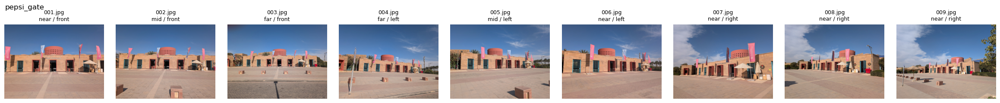

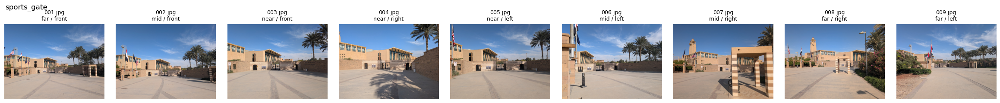

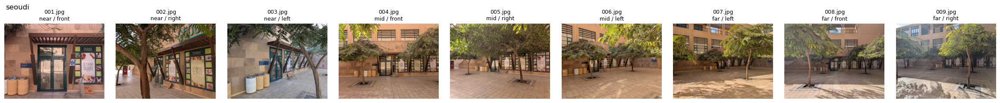

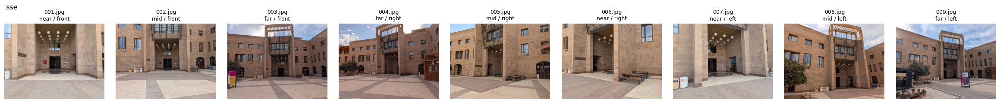

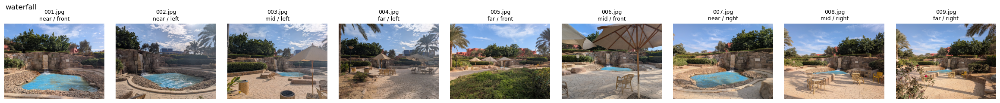

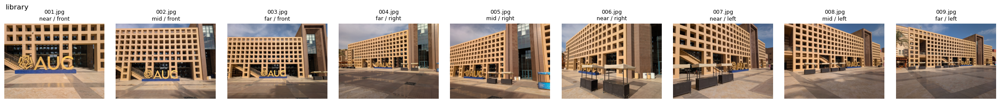

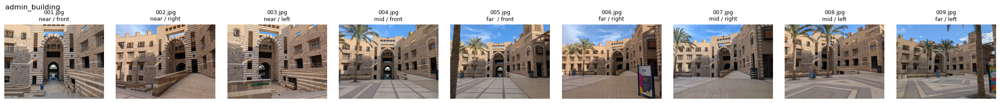

In [6]:
for lm in config.LANDMARKS:
    rows = train[train["landmark"] == lm]
    fig, axes = plt.subplots(1, len(rows), figsize=(2.6 * len(rows), 2.4), squeeze=False)
    for ax, row in zip(axes[0], rows.itertuples()):
        tag = f"{row.distance or '?'} / {row.angle or '?'}"
        show(load_image(row.filename, landmark=lm), f"{row.filename.rsplit('_', 1)[1]}\n{tag}", ax=ax)
        ax.title.set_fontsize(9)
    fig.suptitle(lm, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

## Step 2 · Keypoints: Harris vs SIFT

Harris finds corners only. SIFT finds blob-like points at several scales and gives each
one a 128-number descriptor, which is what makes matching possible.

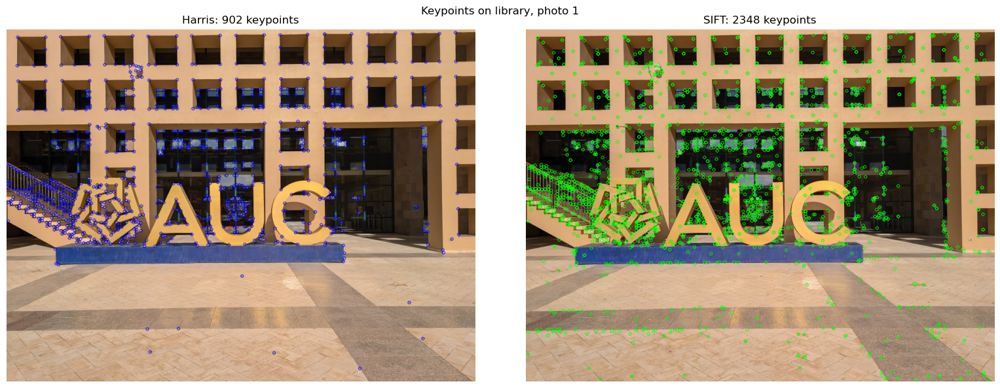

In [7]:
img = photo(DEMO_LANDMARK, 1)
harris = detect_harris(img)
sift, _ = detect_sift(img)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, kps, name, color in [(axes[0], harris, "Harris", (255, 0, 0)),
                             (axes[1], sift, "SIFT", (0, 255, 0))]:
    drawn = cv2.drawKeypoints(img, kps, None, color=color)
    show(drawn, f"{name}: {len(kps)} keypoints", ax=ax)
fig.suptitle(f"Keypoints on {DEMO_LANDMARK}, photo 1")
fig.tight_layout()
save_figure(fig, "keypoints_harris_vs_sift")
plt.show()

### Repeatability

For two photos of the same landmark, the homography from SIFT + RANSAC maps every point of
photo A into photo B. A keypoint counts as **found again** if B has its own keypoint within
3 px of where it lands. Higher is better.

*Lighting is not compared yet: all photos so far are from the morning set.*

In [8]:
def pairs_for(lm):
    """(change, file A, file B) pairs of one landmark, chosen from labels.csv:
    angle: same distance, different angle; distance: same angle, different distance.
    Without labels, falls back to photo 1 vs the next 4, marked "unlabelled"."""
    rows = train[train["landmark"] == lm].reset_index(drop=True)
    labelled = rows[(rows["distance"] != "") & (rows["angle"] != "")]
    if len(labelled) < 2:
        return [("unlabelled", rows.filename[0], f) for f in rows.filename[1:5]]
    out = []
    for change, same, diff in [("angle", "distance", "angle"), ("distance", "angle", "distance")]:
        found = [(a.filename, b.filename) for a in labelled.itertuples() for b in labelled.itertuples()
                 if a.filename < b.filename and getattr(a, same) == getattr(b, same)
                 and getattr(a, diff) != getattr(b, diff)]
        out += [(change, fa, fb) for fa, fb in found[:3]]
    return out

rows = []
for lm in config.LANDMARKS:
    for change, fa, fb in pairs_for(lm):
        a, b = load_image(fa, landmark=lm), load_image(fb, landmark=lm)
        H = match_images(a, b)["H"]
        if H is None:
            print(f"{lm} {fa} vs {fb}: no homography found, skipped"); continue
        rows.append({"landmark": lm, "change": change, "photo A": fa, "photo B": fb,
                     "Harris": repeatability(a, b, H, detect_harris),
                     "SIFT": repeatability(a, b, H, sift_keypoints)})
rep = pd.DataFrame(rows)
rep.round(3)

pepsi_gate pepsi_gate_2026-11-26_001.jpg vs pepsi_gate_2026-11-26_008.jpg: no homography found, skipped
sports_gate sports_gate_2026-11-26_001.jpg vs sports_gate_2026-11-26_008.jpg: no homography found, skipped
seoudi seoudi_2026-11-26_001.jpg vs seoudi_2026-11-26_002.jpg: no homography found, skipped
waterfall waterfall_2026-11-26_002.jpg vs waterfall_2026-11-26_007.jpg: no homography found, skipped


,landmark,change,photo A,photo B,Harris,SIFT
0,pepsi_gate,angle,pepsi_gate_2026-11-26_001.jpg,pepsi_gate_2026-11-26_006.jpg,0.244,0.202
1,pepsi_gate,angle,pepsi_gate_2026-11-26_001.jpg,pepsi_gate_2026-11-26_007.jpg,0.157,0.188
2,pepsi_gate,distance,pepsi_gate_2026-11-26_001.jpg,pepsi_gate_2026-11-26_002.jpg,0.525,0.360
3,pepsi_gate,distance,pepsi_gate_2026-11-26_001.jpg,pepsi_gate_2026-11-26_003.jpg,0.432,0.341
4,pepsi_gate,distance,pepsi_gate_2026-11-26_002.jpg,pepsi_gate_2026-11-26_003.jpg,0.457,0.375
5,sports_gate,angle,sports_gate_2026-11-26_001.jpg,sports_gate_2026-11-26_009.jpg,0.185,0.303
6,sports_gate,angle,sports_gate_2026-11-26_002.jpg,sports_gate_2026-11-26_006.jpg,0.253,0.307
7,sports_gate,distance,sports_gate_2026-11-26_001.jpg,sports_gate_2026-11-26_002.jpg,0.287,0.358
8,sports_gate,distance,sports_gate_2026-11-26_001.jpg,sports_gate_2026-11-26_003.jpg,0.207,0.319
9,sports_gate,distance,sports_gate_2026-11-26_002.jpg,sports_gate_2026-11-26_003.jpg,0.265,0.341


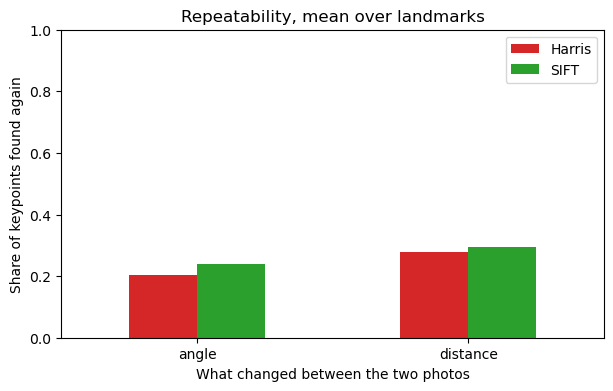

,Harris,SIFT
change,,
angle,0.203,0.238
distance,0.278,0.293


In [9]:
summary = rep.groupby("change")[["Harris", "SIFT"]].mean()
ax = summary.plot.bar(figsize=(7, 4), rot=0, color=["tab:red", "tab:green"])
ax.set_ylabel("Share of keypoints found again")
ax.set_xlabel("What changed between the two photos")
ax.set_ylim(0, 1)
ax.set_title("Repeatability, mean over landmarks")
save_figure(ax.figure, "repeatability")
plt.show()
summary.round(3)

## Step 3 · Matching: ratio test, then RANSAC

**Ratio test**: a match is kept only if its nearest descriptor is clearly closer than the
second nearest (ratio 0.75). **RANSAC** then fits a homography and drops matches that
disagree with it. The top image shows matches after the ratio test, the bottom only the RANSAC inliers.

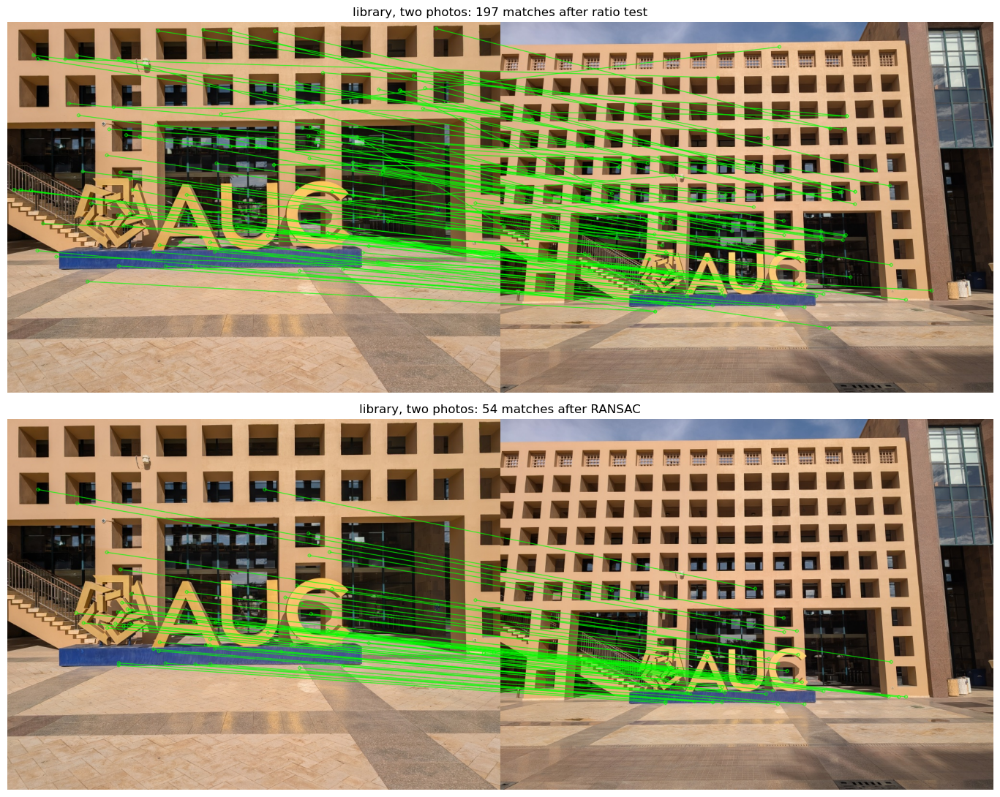

In [10]:
a, b = photo(DEMO_LANDMARK, 1), photo(DEMO_LANDMARK, 2)
fig = draw_before_after(a, b, f"{DEMO_LANDMARK}, two photos")
save_figure(fig, "matches_same_landmark")
plt.show()

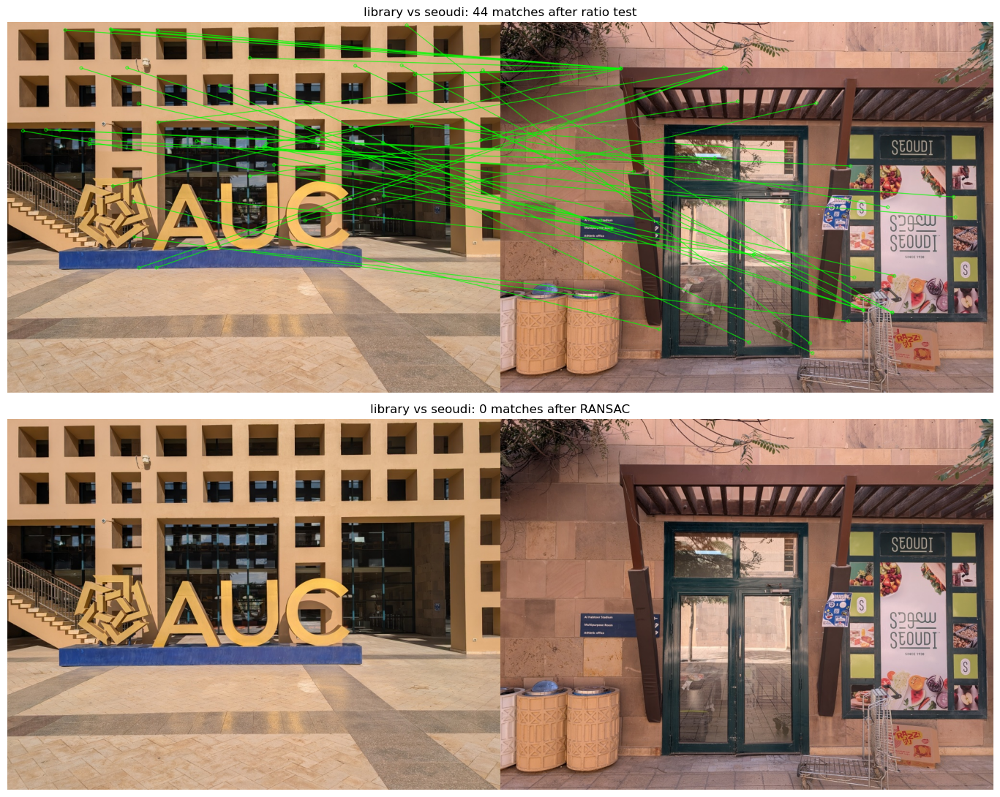

In [11]:
c = photo(OTHER_LANDMARK, 1)
fig = draw_before_after(a, c, f"{DEMO_LANDMARK} vs {OTHER_LANDMARK}")
save_figure(fig, "matches_different_landmarks")
plt.show()

### Good matches between every pair of landmarks

Rows: photo 1 of each landmark. Columns: photo 5 of each landmark. If SIFT matching can tell
landmarks apart, the diagonal (same landmark) is much brighter than the rest. This is the
idea behind Method A.

[load_dataset] train: 63 photos


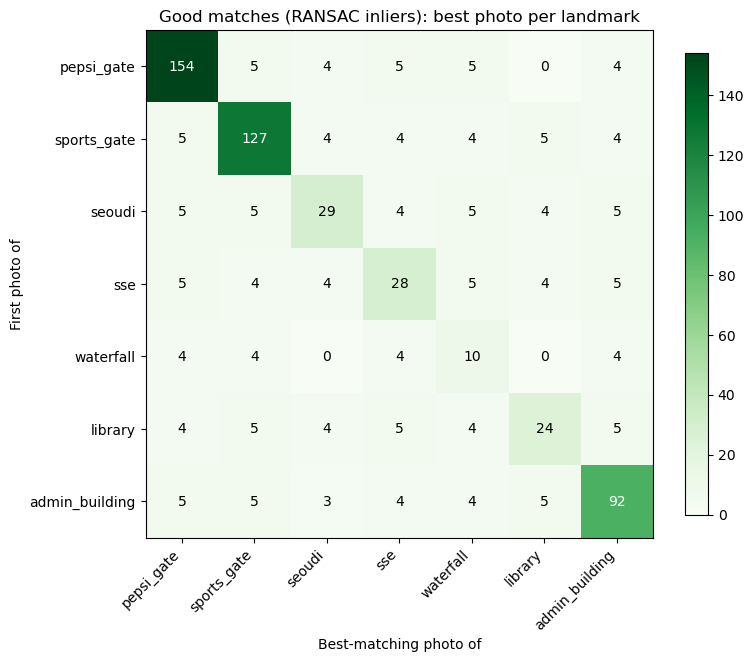

In [12]:
imgs, lbls, fnames = load_dataset("train")
ref = build_reference(imgs, lbls)            # SIFT once per photo, reused below

n = len(config.LANDMARKS)
grid = np.zeros((n, n), dtype=int)
for r, lm_a in enumerate(config.LANDMARKS):
    q = lbls.index(lm_a)                      # first photo of landmark A
    counts = match_counts(imgs[q], ref)
    for c, lm_b in enumerate(config.LANDMARKS):
        grid[r, c] = max(cnt for i, (cnt, lab) in enumerate(counts)
                        if lab == lm_b and i != q)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(grid, cmap="Greens")
ax.set_xticks(range(n), config.LANDMARKS, rotation=45, ha="right")
ax.set_yticks(range(n), config.LANDMARKS)
for r in range(n):
    for c in range(n):
        ax.text(c, r, grid[r, c], ha="center", va="center",
                color="white" if grid[r, c] > grid.max() / 2 else "black")
ax.set_xlabel("Best-matching photo of")
ax.set_ylabel("First photo of")
ax.set_title("Good matches (RANSAC inliers): best photo per landmark")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
save_figure(fig, "match_count_grid")
plt.show()



## Preview · Method A (leave-one-out on the training photos)

Each training photo is predicted from all the *other* training photos.
**This is not our result**: photos taken minutes apart are near-copies, so this score is too
high. The real accuracy comes from the test sets on 30 Nov. Takes a few minutes.

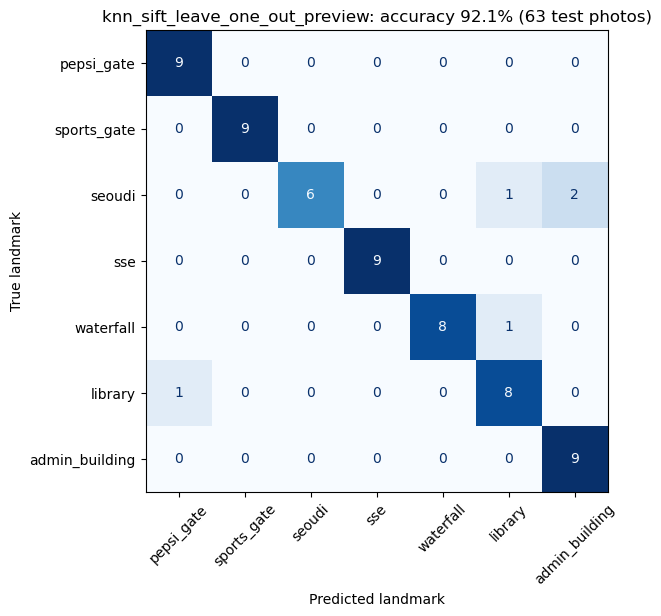

knn_sift_leave_one_out_preview: accuracy 0.921


0.9206349206349206

In [13]:
pred = []
for i, img in enumerate(imgs):
    counts = match_counts(img, ref)
    pred.append(vote(counts[:i] + counts[i + 1:])[0])
evaluate(lbls, pred, "knn_sift_leave_one_out_preview")

## Next steps

- **29–30 Nov**: sunset training set, then the two test sets (morning and sunset)
- **Method A**: KNN on good-match counts, real accuracy on the test sets
- **Method B**: color histogram and PCA features with SVM and MLP
- **Repeatability under lighting change**, once the sunset set exists
- **Panorama** from the library set
- **Evaluation**: accuracy table, confusion matrices, at least three failure cases